# Т-Интенсив. Управление рисками
## Август 2026

## Часть 1. График линейности признака по WoE.

В этой части домашки мы познакомимся с одним из основных инструментов для анализа переменных в модели логистической регрессии - графиком линейности. 

Кратко идею этого графика можно сформулировать так:
 - модель *линейной* регрессии корректно применять, если значение $y$ *линейно* связано со значением $x$. Иначе линрег не подходит для данной задачи и даст неверные результаты.
 - аналогичную проверку хочется сделать и для *логистической* регрессии. Но как проверить линейность, если таргет принимает всего два значения?
 - для этого необходимо преобразовать таргет: разбить признак на бакеты и в каждом бакете посчитать WoE
 - **линейность признака по WoE для логрега – аналог линейной связи признака и таргета для линрега**

Ниже пример признака с неплохой линейностью:

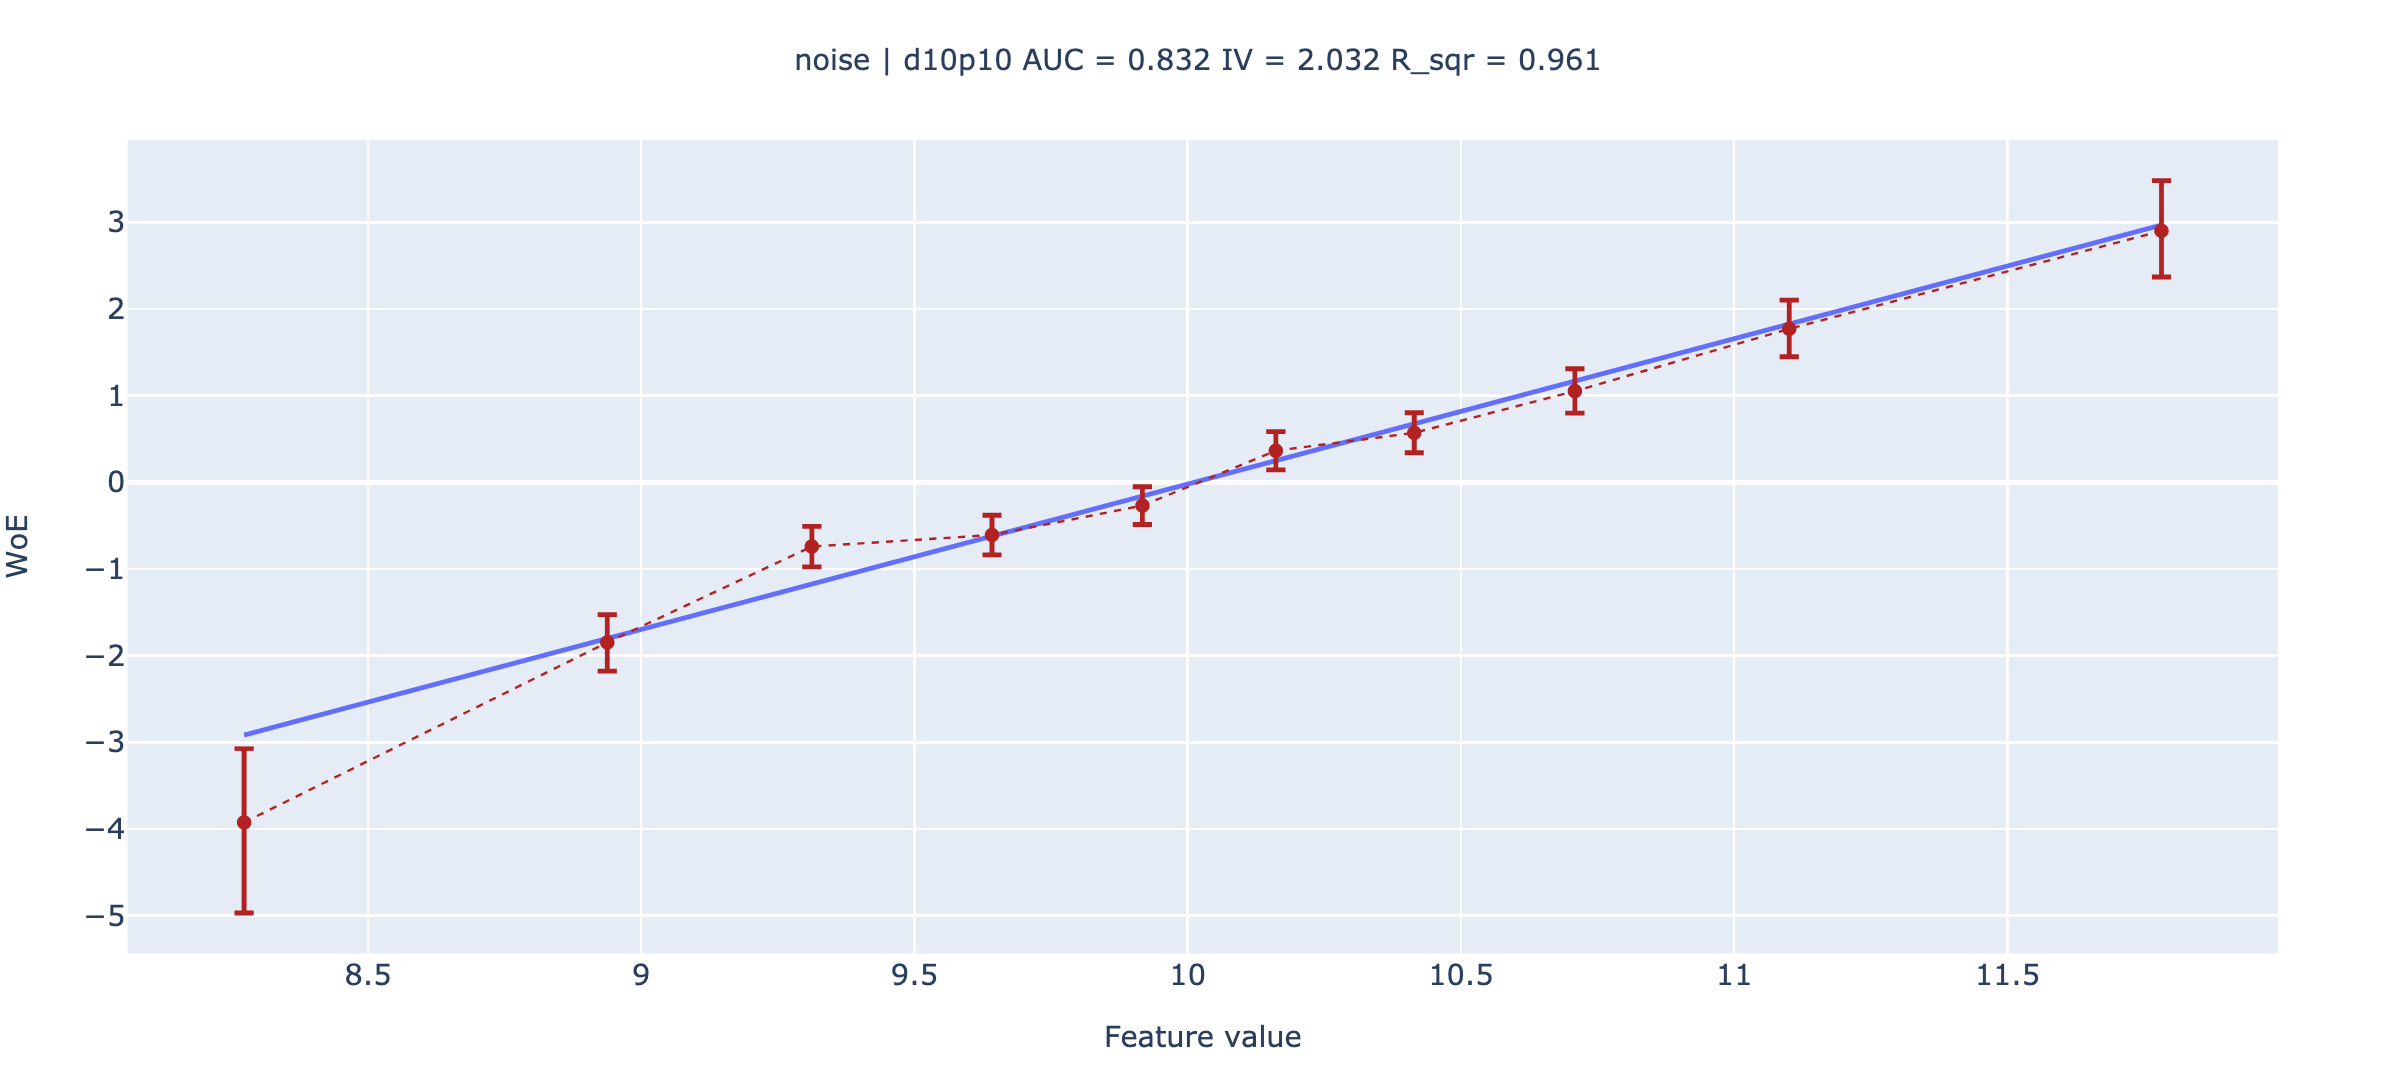

Нам нужно обратить внимание на 3 вещи:

**1. Фиолетовые точки с доверительными интервалами.**

Это WoE для каждого отдельного бакета. В идеале нам бы хотелось, чтобы **через эти точки можно было провести прямую линию** с небольшой погрешностью. Это и означает линейную взаимосвязь с таргетом.

**2. Синяя линия**

Попытка провести прямую линию через точки. Строится с помощью логистической регрессии на одной переменной. Затем предсказания переводятся в пространство WoE, отчего и получается прямая линия.

**3. Метрики в заголовке графика**

Метрики для признака:
 - roc auc, IV измеряют разделяющую способность переменной
 - $R^2$ измеряет *линейность взаимосвязи*. Признак считается линейным, если $R^2 \geq 0.95$

Далее напишем woe-line руками, чтобы в деталях разобраться, как он строится.

In [4]:
import numpy as np
import pandas as pd
import seaborn as sns
import scipy.stats as sps
from typing import Union, Tuple

### Шаг 0: разбиение на бакеты

In [5]:
def calc_buckets(x : Union[np.ndarray, pd.Series], n_buckets : int) -> np.ndarray:
    """Разбивает массив значений признака x на 
    n_buckets бакетов"""

    x = pd.Series(x).reset_index(drop=True)
    buckets = x.rank(method="dense", pct=True) * n_buckets
    buckets = np.ceil(buckets) - 1   # np.floor дает другой результат для 5.0, 6.0 и т.д.
    buckets = np.array(buckets, dtype=np.int16)

    return buckets

In [6]:
# протестируйте calc_buckets
x_test = np.random.random(size = 10_000) * 10_000
print(x_test)

buckets = calc_buckets(x_test, n_buckets=100)
buckets.shape, buckets

[ 297.16354296 8565.62047989 2517.94273672 ... 1034.02315091 5171.55306468
 9147.78686241]


((10000,), array([ 2, 85, 24, ...,  9, 52, 91], dtype=int16))

### Шаг 1: расчет WoE по бакетам (3 балла)

Пусть $x_i \in \{ 0, 1\}^n$

$x_i$ - это вектор, состоящий из значений таргета *в одном бакете* $i$. 

Для бакета можно посчитать количество единиц $B_i$ (bads, выпавшие в дефолт) и количество нулей $G_i$ (goods).

$$
B_i = \sum_{j \in x_i} \mathbb{I} \{ j = 1\}\quad G_i = \sum_{j \in x_i} \mathbb{I} \{ j = 0\}
$$

Также число бэдов и гудов можно посчитать и **для всей выборки**: 

$$
% X = x_1 \cup x_2 \ldots \cup x_n
X = \{x_1,\; x_2\; \ldots\; x_n\}
$$

$$
B = \sum_{j \in X} \mathbb{I} \{ j = 1\}\quad G = \sum_{j \in X} \mathbb{I} \{ j = 0\}
$$

Тогда WoE можно посчитать как

$$
\text{WoE}_i(x) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big ) 
$$

**Задание**

Убедиться, что

$$
\text{WoE}_i(x) = \text{logit}(b_i) - \text{logit}(b)\quad  (1)
$$

где 

$$
b = \frac{B}{B + G}\quad \text{logit}(p) = \ln \Big (  \frac{p}{1 - p} \Big )
$$

В дальнейшем будем считать WoE по формуле $(1)$

In [7]:
from scipy.special import logit

def woe_transform(badrate : float, offset : float) -> float:
    """Считаем WoE для бакета с данным badrate и выборки
    с данным offset."""
    woe = logit(badrate) - offset
    return woe

Здесь и далее предлагается протестироать получившиеся функции. Нужно проверить, что
 - функция не ложится с ошибкой
 - возвращает то, что ожидается

<div align="center">
  Важное замечание!

  Я решил написать это здесь, потому что, кажется, ровно здесь и начинается первая уже авторская писанина, которую будут проверять $\Rightarrow$ будут отсматривать. Мне немного было больно от формализации терминов, потому что местами встречаются опечатки, а местами сделан резкий переход от многомерного случая к одномерному, из-за которого при просмотре конспекта я долго медитировал.
</div>

Пусть у нас есть две случайных величины $\xi = (\xi_1, ..., \xi_n), y$, причём они зависимые, то есть у них существует какое-то совместное распределение $P_{\xi \cdot y}$. Мы хотим сделать так, чтобы $w^T\xi \approx \ln(\frac{P(y = 1 | \xi)}{P(y = 0 | \xi)})$, но если мы предполагаем, что фичи независимы в совокупности, то случайная величина справа в силу теоремы Байеса превращается в:
$$
\ln(\frac{P(y = 1 | \xi)}{P(y = 0 | \xi)}) = \sum_{i=1}^n [\ln(\frac{P(y = 1 | \xi_i)}{P(y = 0 | \xi_i)}) - \ln(\frac{P(y = 1)}{P(y = 0)})] + \ln(\frac{P(y = 1)}{P(y = 0)}) =: \sum_{i = 1}^n \text{WoE}(\xi_i) + \ln(\frac{P(y = 1)}{P(y = 0)})
$$
Поэтому будем считать, что $\text{WoE}(\xi_i) =: \text{WoE}_i$ - это случайная величина, зависимая от $\xi_i$, соответственно, если мы пишем $\text{WoE}_i(x)$, то мы имеем в виду, что $\text{WoE}_i(x) = \ln(\frac{P(\xi_i = x | y = 1)}{P(\xi_i = x | y = 0)}) = \ln(\frac{P(y = 1 | \xi_i = x)}{P(y = 0 | \xi_i = x)}) - \ln(\frac{P(y = 1)}{P(y = 0)})$. Поэтому нам важна линейность $\text{WoE}_i$ от $\xi_i \ \forall i$, потому что тогда лог-шанс действительно превращается во что-то линейное от $\xi$, и всё становится классно.

<div align="center">
    Конец важного замечания!

    P.S Я действительно потратил 20 минут, чтобы сказать, что $\text{WoE}_i(x)$ - это конкретная реализация случайной величины от конкретной фичи, спасибо за внимание! 
</div>

Протестируем стандартно: сгенерируем выборку из смешного распределения, разобьём её по бакетам функцией с прошлого шага, поинтересуемся состоянием 42-ого бакета. Кроме того, сделаем какой-то необычный бинарный таргет, прогоним изначальную формулу, посчитав WoE вручную, затем прогоним через новую функцию.

In [53]:
# протестируй woe_transform
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500
print(sample, target.mean())

buckets = calc_buckets(sample, n_buckets = 100)
bucket_s = sample[buckets == 42]
bucket_t = target[buckets == 42]

bads = bucket_t.sum()
goods = len(bucket_t) - bads

old_form = np.log(bads / goods) - np.log(target.sum() / (len(target) - target.sum()))
print(f"Значение, посчитанное через изначальную формулу:\n{old_form}")

new_form = woe_transform(bads / len(bucket_t), offset=logit(target.sum() / len(target)))
print(f"Значение, посчитанное через логиты:\n{new_form}")

print(f"Примерно равны ли:\n{np.isclose(new_form, old_form)}")

[11394.39480405  8797.66095862 10624.13204897 ...  9144.53585261
 13419.38256414 11266.28910981] 0.596
Значение, посчитанное через изначальную формулу:
-1.284209836159041
Значение, посчитанное через логиты:
-1.2842098361590408
Примерно равны ли:
True


### Доверительные интервалы (3 балла)

Ниже представлен шаблон функции, которая будет считать доверительный интервал к нашим вычислениям. Можно воспользоваться любым способом, который вам больше нравится. Для идей можно посмотреть различные способы подсчета доверительного интервала [здесь](https://en.wikipedia.org/wiki/Binomial_proportion_confidence_interval).

**P. S.**
Для того, чтобы построить доверительный интервал к $WoE$, можно сначала построить его для величины  $b_i = \frac{B_i}{B_i+G_i}$, а потом применить ```woe_transform```. В свою очередь величина $b_i$ является параметром распределения Бернулли, который мы можем оценить классическими методами (см. ссылку выше)

Будем использовать вполне стандартный метод построения: Метод Вальда. Пусть мы интересумся каким-то конкретным бакетом таргета $y_i$ (например, $\xi_j$ принимает в этом бакете значения $x_i$, поэтому нас это интересует). Этот бакет мы можем представить в виде выборки $(X_1, \dots, X_m), \ X_i \sim^{\text{iid}} Bern(b_i)$. Тогда на этот параметр мы можем построить следующий доверительный интервал, пусть $S_m := \sum_{i=1}^m X_i$:
$$
P_{b_i} ([\frac{S_m}{m} - \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}, \frac{S_m}{m} + \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}]) = 1 - \alpha
$$
Но мы делаем оценку на $\text{WoE}_j(x_i) = logit(b_i) - logit(b)$, где $b$ - это оценка на распределение Бернулли всей выборки, поэтому наш итоговый интервал будет иметь вид:
$$
P_{\text{WoE}_j(x_i)}([logit(\frac{S_m}{m} - \frac{z_{1 - \frac{\alpha}{2}} \sqrt{S_m(m-S_m)}}{m\sqrt{m}}) - logit(b), logit( \frac{S_m}{m} + \frac{z_{1 - \frac{\alpha}{2}}\sqrt{S_m(m-S_m)}}{m\sqrt{m}}) - logit(b)]) = 1 - \alpha
$$

In [12]:
def woe_ci(target : np.ndarray, buckets : np.ndarray, offset : float) -> Tuple[pd.Series]:
    """Для каждого бакета вычисляем WoE и доверительный
    интервал для него."""
    # считаем бэдрейт и доверительный интервал для него (любым способом)
    badrate, badrate_lower, badrate_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
        badrate[bucket] = target[buckets == bucket].mean()
        add_val = sps.norm.ppf(1 - 0.05 / 2, loc = 0, scale = 1) * ((badrate[bucket]) * (1 - badrate[bucket]) / len(target[buckets == bucket]))**0.5
        badrate_lower[bucket] =  badrate[bucket] - add_val
        badrate_upper[bucket] =  badrate[bucket] + add_val

    # переходим от бэдрейта к woe
    woe, woe_lower, woe_upper = pd.Series([]), pd.Series([]), pd.Series([])
    for bucket in sorted(set(buckets)):
            woe[bucket] = woe_transform(badrate=badrate[bucket], offset=offset)
            woe_lower[bucket] = woe_transform(badrate = badrate_lower[bucket], offset = offset)
            woe_upper[bucket] = woe_transform(badrate = badrate_upper[bucket], offset=offset)
    return woe, woe_lower, woe_upper

### Шаг 2: расчет линейной интерполяции (1 балл)

In [ ]:
from sklearn.linear_model import LogisticRegression

def calc_line(values : np.ndarray, target : np.ndarray, mean_feature : np.ndarray, offset : float) -> np.ndarray:
    """Строим линейную интерполяцию для WoE."""

    # строим логистическую регрессию на одном признаке
    # и считаем ее предсказания в точках – mean_feature

    model = LogisticRegression()
    model = model.fit(values.reshape(-1, 1), target) # reshape, иначе ругается sklearn

    # .predict_proba возвращает матрицу (n_samples, n_classes)
    # простыми словами он возращает матрицу вида:
    # (P(y = 0 | x_1), P(y = 1 | x_1))
    # (...)
    # (P(y = 0 | x_n), P(y = 1 | x_n))
    # Так как в логреге мы интересуемся P(y = 1 | X), 
    # то и берём мы только второй столбец.

    proba = model.predict_proba(mean_feature.reshape(-1, 1))[:, 1]
    line = woe_transform(proba, offset)
    return line

In [34]:
# протестируйте calc_line
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500

buckets = calc_buckets(sample, n_buckets = 100)
mean_feature = []

for i in range(100):
    mean_feature.append(sample[buckets == i].mean())

res = calc_line(sample, target, np.array(mean_feature), logit(target.mean()))
res, res.shape

(array([ 0.01877252,  0.01838442,  0.01796164,  0.01757959,  0.01718905,
         0.0168078 ,  0.01644895,  0.01601722,  0.01556401,  0.01520565,
         0.01485319,  0.01450299,  0.01410596,  0.01377433,  0.0133872 ,
         0.01297674,  0.01259897,  0.01226697,  0.0118758 ,  0.01151551,
         0.01110495,  0.0107418 ,  0.01039911,  0.01003862,  0.00960914,
         0.00925484,  0.00890392,  0.00856253,  0.00822011,  0.00788456,
         0.00751206,  0.00717383,  0.00684723,  0.00644881,  0.00609215,
         0.00564726,  0.00527944,  0.00492512,  0.00460556,  0.00423874,
         0.00383863,  0.00340069,  0.00298614,  0.00261262,  0.00220094,
         0.00185813,  0.00150365,  0.00110989,  0.0007507 ,  0.00029625,
        -0.00014028, -0.00055322, -0.00097303, -0.0013759 , -0.00175317,
        -0.00209125, -0.00248687, -0.00285556, -0.00321536, -0.0035804 ,
        -0.00394755, -0.00433983, -0.00470723, -0.00509279, -0.00547554,
        -0.0058916 , -0.00625519, -0.00666939, -0.0

### Шаг3: собираем результаты по бакетам в один словарь

In [54]:
def calc_buckets_info(values : np.ndarray, target : np.ndarray, buckets : np.ndarray) -> dict:
    """Для каждого бакета расчитывает
     - среднее значение признака
     - линейную интерполяцию в пространстве woe
     - значение woe и доверительный интервал для него"""

    mean_feature = np.array([values[buckets == i].mean() for i in range(len(set(buckets)))])
    offset = logit(target.mean())
    woe, woe_lower, woe_upper = woe_ci(target, buckets, offset)
    buckets_info = {
        "mean_feature" : mean_feature,
        "line"         : calc_line(values, target, mean_feature, offset),
        "woe"          : woe,
        "woe_lower"    : woe_lower,
        "woe_upper"    : woe_upper
    }

    return buckets_info

In [58]:
# протестируйте calc_buckets_info
sample = np.random.random(size = 10_000) * 10_000 + np.random.normal(loc=5000, scale=70)
target =  np.round(sample % 1337) >= 500
buckets = calc_buckets(sample, n_buckets = 100)

calc_buckets_info(sample, target, buckets)["woe"]

0          inf
1          inf
2          inf
3    -1.274851
4         -inf
        ...   
95         inf
96    2.955020
97        -inf
98        -inf
99        -inf
Length: 100, dtype: float64

Тут не стоит пугаться бесконечностей, потому что бывает, что в бакетах вообще нет бэдов или нет гудов, из-за чего всё взрывается.

### Шаг 4: считаем метрики признака (3 балла)

Рассчитаем также несколько метрик, чтобы судить о качестве признака не только по картинкам. 

Приведем формулу для IV:

$$
\text{IV}(x) = \sum_{i = 1}^{n}\Big ( \frac{B_i}{B} - \frac{G_i}{G} \Big ) \times \text{WoE}_i
$$

**Вопрос:** зачем считать ранжирующую силу признака двумя способами? Какую дополнительную информацию может дать IV относительно roc auc?

Продолжаем наши формализационные приключения, теперь мы пришли к IV - по сути детерменированному функционалу от фичи, пусть у нас $\xi_i$ - абсолютно непрерывная (или дискретная) случайная величина, тогда:
$$
IV_i := IV(\xi_i) = D_{KL}(p_{\xi | y = 1} || p_{\xi | y = 0}) + D_{KL}(p_{\xi | y = 0} || p_{\xi | y = 1}) = \int_{\mathbb{R}} [P(\xi_i = x | y = 1) - P(\xi = x | y = 0)] \cdot \text{WoE}_i(x) dx
$$
Для дискретной, очевидно, интеграл превратится в сумму. Тогда отсюда как раз та формула оценки на IV для i-oй дискретной фичи ($\xi_i \in \{x_1, \dots, x_m\}$):
$$
\overline {IV_i} = \sum_{j=1}^m [\frac{B_j}{B} - \frac{G_j}{G}] \cdot \text{WoE}_i(x_j)
$$

**Ответ**:
Будем считать, что мы рассуждаем в контексте одной фичи. Если выполнены сильные предпосылки (например, нормальные распределения с одинаковыми дисперсиями), то одна метрика выражается через другую, однако в общем случае эти две метрики используются для немного разных целей: ROC-AUC считает, насколько фича хорошо ранжирует в целом, она даёт информацию о глобальном порядке, поэтому сравнивать силу признаков через эту метрику можно только в смысле общей ранжирующей способности; IV же в свою очередь позволяет сравнивать признаки между собой и выбирать наиболее информативные, например, чем больше эта метрика, тем сильнее отличаются условные распределения (потому что дивергенции как раз расстояния между распределениями и считает), а значит, вполне может быть такое, что некоторые значения для $y = 1$ будут появляться у фичи настолько редко, но при этом настолько часто при $y = 0$, что по каким-то конкретным значениям можно будет сразу сказать о наиболее вероятном классе, подобной информации о разнице распределений не может показать roc-auc. Кроме того, IV показывает вклад по бакетам, поэтому мы получаем ещё больше локальной информации о фиче. Поэтому ранжирующую силу можно считать двумя способами: одним для общей картины, другим для конкретных особенностей.

In [ ]:
from sklearn.metrics import roc_auc_score

def calc_plot_title(
        values : np.ndarray,
        target : np.ndarray,
        buckets : np.ndarray
    ) -> str:
    """Считает для признака roc auc, IV, R^2"""
    auc = None

    # формула выше
    IV = None

    # Взвешенный R^2 
    # X - среднее в бакете, Y - woe в бакете, вес – число наблюдений в бакете
    R_sqr = None

    plot_title = (        
        f"AUC = {auc:.3f} "
        f"IV = {IV:.3f} "
        f"R_sqr = {R_sqr:.3f} "
    )

    return plot_title

In [ ]:
# протестируйте calc_plot_title

### Шаг 5: собираем все в одну функцию и строим график

In [ ]:
# в этот код можно не въезжать :)
import plotly.graph_objects as go

def make_figure(buckets_info : dict, plot_title : str) -> go.Figure:
    """Строит график линейности."""
    fig = go.Figure()

    # общие настройки
    title = dict(
        text=plot_title,
        y=0.95,
        x=0.5,
        font=dict(size=12),
        xanchor="center",
        yanchor="top"
    )
    margin = go.layout.Margin(
        l=50,
        r=50,
        b=50,
        t=60
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["line"],
            mode='lines',
            name="interpolation_line",
            showlegend=False
        )
    )

    fig.add_trace(
        go.Scatter(
            x=buckets_info["mean_feature"],
            y=buckets_info["woe"],
            line=dict(
                color='firebrick',
                width=1,
                dash='dot'
            ),
            error_y=dict(
                type='data',
                symmetric=False,
                array=buckets_info["woe_upper"],
                arrayminus=buckets_info["woe_lower"]
            ),
            name="WoE",
            showlegend=False)
    )

    fig.update_layout(
        width=1000,
        height=450,
        xaxis_title=dict(
            text='Feature value',
            font=dict(size=12)
        ),
        yaxis_title=dict(
            text="WoE",
            font=dict(size=12)
        ),
        title=title,
        margin=margin
    )

    return fig

In [ ]:
def woe_line(
        values : np.ndarray,
        target : np.ndarray,
        n_buckets : int
    ) -> go.Figure:
    """График линейности переменной по WoE."""
    buckets : np.ndarray = calc_buckets(values, n_buckets)
    buckets_info : pd.DataFrame = calc_buckets_info(values, target, buckets)
    plot_title : str = calc_plot_title(values, target, buckets)
    fig = make_figure(buckets_info, plot_title)
    return fig

Чтобы протестировать реализацию, сгенерируем синтетические данные:

In [ ]:
sample_size = int(1e4)
noise_std = 1.

df = pd.DataFrame()
y = np.array(sample_size // 2 * [0] + sample_size // 2 * [1])
df['target']  = y

np.random.seed(89)
x = np.concatenate([sps.norm(0, noise_std).rvs(size = sample_size // 2), sps.norm(1, noise_std).rvs(size = sample_size // 2)])
df['feature'] = x

In [ ]:
sns.histplot(df, x = 'feature', hue = 'target')

In [ ]:
# запустите после того, как реализуете все функции 
woe_line(values=x, target=y, n_buckets=5)

### Эксперименты (2 балла)

#### №1 

Как будут меняться график, метрики разделяющей способности и $R^2$ при изменении дисперсии шума (параметр `noise_std`)? 

#### №2 

Запустите функцию с `values=x ** 2`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

#### №3

Запустите функцию с `values=np.exp(x)`. Как по графику определить эту ситуацию? Что нужно делать в таком случае?

## Часть 2. Строим ЛогРег. (8 баллов)

В этом пунтке попробуем применить все наши навыки 

Скачайте датасет на EDU. Пароль вы найдете в телеграм-канале курса, в посте с анонсом домашки.

In [32]:
df = pd.read_csv('logreg_hw_5.csv', index_col=0)
df

,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,feature_10,feature_11,feature_12,feature_13,feature_14,feature_15,d4p12
0,-1.444709,3.554779,1.308371,-0.000119,0.029628,3.829880,1,8.825418,3.829880,11.565953,-513.014565,-1.072893,7.936545,0.047069,B,1
1,1.132531,-0.207661,-2.142882,0.062686,0.859062,6.189545,1,3.453220,6.189545,4.935665,-39.351891,3.409855,17.015210,0.029288,A,0
2,1.268781,-0.243999,10000.000000,0.339225,0.614599,12.503629,1,-10.116061,12.503629,6.234414,-4.993050,3.121126,4.878602,0.237255,A,0
3,-1.278475,-2.579890,5.050763,-0.938956,0.090461,-1.080041,1,6.780814,-1.080041,2.682539,-509.273095,-1.242741,20.293025,0.907788,B,0
4,3.507807,0.152661,-8.905005,0.067646,0.216199,1.367184,1,-10.638134,1.367184,6.881602,-2.034797,2.814972,7.352399,0.276854,A,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
99995,-3.061422,-0.163832,4.812768,-0.949937,0.224437,5.263508,1,-9.959913,5.263508,5.294558,-524.265291,-1.648415,5.410059,0.855190,B,0
99996,0.222451,-0.273191,0.380895,0.860607,0.950708,0.581767,1,-1.645952,0.581767,5.571499,-13.499956,3.386865,92.903615,0.006668,A,1
99997,1.078498,0.339526,-5.184847,0.242072,0.854085,0.995075,1,-5.565932,0.995075,-0.433263,3.928387,3.290285,1.233853,0.160933,A,1
99998,-1.431421,-0.605388,2.466023,-0.056519,0.736255,2.980562,1,-4.517188,2.980562,10.812813,-507.593408,-1.398568,1904.246147,0.077164,B,1


Как вы выдите, ```feature_1, ..., feature_14``` - числа 
```feature_15``` - категориальная фича

### Задание 0. EDA.

Как бы вы начали знакомиться с данными до построения модели? Постройте 3-5 графиков / таблиц, чтобы передать основную информацию о датасете.

In [ ]:
df.columns

### Задание 1. Бейзлайн.

Попробуйте построить ЛогРег только на числовых данных. Для этого разбейте датасет на трейн и тест (80/20). Перед обучением логрега стандартизуйте переменные. Это может быть полезно для численной устойчивости алгоритмов оптимизации.

Для этой модели и всех дальнейших:

1. Получилась ли модель линейной? Постройте график линейности на трейне и на тесте и сделайте вывод.
2. Расчитайте AUC и IV на трейне и на тесте. Что можно сказать о переобучении?

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

### Задание 2. Добавляем категориальную переменную.

Повторите задание 1, включив в модель категориальную переменную (например, с помощью one-hot encoding).

Улучшилось ли качество?

### Задание 3. Линеаризация переменных.

На самом деле, категориальные переменные можно учитывать в моделях совсем по-другому. С их помощью можно выделить в модели сегменты. Каждому сегменту соответствует своя модель (в нашем случае логрег). 

Примером такой сегментации может стать сегментация по наличию кредитной истории. В этом случае на разных сегментах будут не просто отдельные модели, но и даже разный изначальный набор признаков. Другое свидетельство удачной сегментации – разный характер зависимости признаков и целевой переменной. Это можно увидеть на графике линейности признака по WoE. Этим мы и займемся далее.

Используйте переменную 15 для сегментации модели. На каждом из двух сегментов линеаризуйте переменные. Для этого приложите:
 - график линейности переменной до преобразования
 - график после подобранного преобразования

Помимо этого:
 - попробуйте линеаризовать какие-нибудь 2 переменные *на всей выборке*. Получилось ли у вас что-то? Постройте график.
 - по графику линейности определите шумовые (либо слабоинформативные) переменные. В конце задания приложите их список.

### Задание 4. Финальная модель.

Обучите модели на признаках, которые вы отобрали и линеаризовали в задании 3. Пусть $logit_A$ – модель, обученная на сегменте $feature_{15} = A$. $logit_B$ – модель на втором сегменте. Тогда модель на всей выборке будем считать по формуле

$$
logit(x) = \mathbb I \{ feature_{15} = A \} \times logit_A(x) + \mathbb I \{ feature_{15} = B \} \times logit_B(x)
$$


Посчитайте для этой модели AUC и IV, оцените линейность на трейне и тесте. Сравните результаты с бейзлайном из задания 1.

Подсказка: если вы все сделали правильно, можно ожидать ROC AUC около 0.9 на тестовой выборке.

# Часть 3. Бонус. (3 балла)

На лекции мы накопили ряд упражнений, которые стоит решить для понимания происходившего. Вы можете $\TeX$ать их прямо в ноуте (или прикреплять картинки, если так удобнее).

#### **Упражнение 1**

Для определения $WoE$ мы пользовались Теоремой Байеса. Примените ее и **покажите, что верно равенство**:

$$
\ln \left(  \frac{P(x_i|y=1)}{P(x_i|y=0)} \right) = ... = \ln \left( \frac{P(y=1|x_i)}{P(y=0|x_i)} \right) - \ln \left( \frac{P(y=1)}{P(y=0)} \right)
$$

Распишем всё подробно:
$$
P(x_i | y = 1) = \frac{P(x_i \cap y = 1)}{ P(y = 1)} = \frac{P(y = 1 | x_i) P(x_i)}{P(y = 1)}
$$
Аналогично:
$$
P(x_i | y = 0) =  \frac{P(x_i \cap y = 0)}{ P(y = 0)} = \frac{P(y = 0 | x_i) P(x_i)}{P(y = 0)}
$$
Мёрджим:
$$
\ln{\frac{P(x_i | y = 1)}{P(x_i | y = 0)}} = \ln(P(x_i | y = 1)) - \ln(P(x_i | y = 0)) = \ln(\frac{P(y = 1 | x_i) P(x_i)}{P(y = 1)}) - \ln(\frac{P(y = 0 | x_i) P(x_i)}{P(y = 0)}) =
$$
$$
= \ln(P(y = 1 | x_i)) + \ln(P(x_i)) - \ln(P(y = 1)) - \ln(P(y = 0 | x_i)) - \ln(P(x_i)) + \ln(P(y = 0)) = \ln(\frac{P(y = 1 | x_i)}{P(y = 0 | x_i)}) - \ln(\frac{P(y = 1)}{P(y = 0)})
$$
Ну и получили нужную формулу.

#### **Упражнение 2**

Известно:

$WoE$ можно посчитать так:
$WoE_i(x_i) = \ln \Big ( \frac{B_i}{G_i} \Big ) - \ln \Big ( \frac{B}{G} \Big ) $

Частота выхода в дефолт:  $badrate = \frac{B}{B+G}; \quad badrate_i = \frac{B_i}{B_i+G_i}$

$
\sigma (x) = \frac{1}{1+e^{-x}}; \quad logit(x) = \ln \left( \frac{x}{1-x} \right)
$

**Покажите, что**
$WoE_i(x_i) = logit(badrate_i) - logit(badrate)$

Распишем формулу для логита:
$$
\text{logit}(badrate) = \text{logit}(\frac{B}{B + G}) = \ln (\frac{\frac{B}{B + G}}{1 - \frac{B}{B + G}}) = \ln (\frac{B}{B + G}) - \ln(\frac{B + G}{B + G} - \frac{B}{B + G}) = \ln(\frac{B}{B + G}) - \ln(\frac{G}{B + G}) = \ln (\frac{B}{G})
$$
Аналогично:
$$
\text{logit}(batrate_i) = \dots = \ln (\frac{B_i}{G_i})
$$
Тогда соберём всё воедино:
$$
\text{logit}(batrate_i) - \text{logit}(batrate) = \ln (\frac{B_i}{G_i}) - \ln (\frac{B}{G}) = \text{WoE}_i(x) \Rightarrow показали.
$$

#### **Упражнение 3**

Пусть даны два дискретных распределения: 

$B=(b_1, ..., b_n)$ и $G=(g_1, ..., g_n)$.

KL-дивергенция для дискретных распределений

$$D_{KL}(B||G) = \sum_{j=1}^{n} b_j \ln \left( \frac{b_j}{g_j} \right)$$


Пусть $x$ - дикретный признак, принмиающий значения $x_1,...,x_n$.
Известно определение IV через KL-дивергенцию:

$$
IV_x = D_{KL}(B_x||G_x)+D_{KL}(G_x||B_x)
$$
где 

$$
B_x (x_i) = P(x=x_i|y=1) = b_i; \quad G_x (x_i) = P(x=x_i|y=0) = g_i
$$

**Выразите $IV$ через $WoE$**





Распишем дивергенцию:
$$
D_{KL}(B_x || G_x) = \sum_{i=1}^n b_i \ln(\frac{b_i}{g_i}) = \sum_{i=1}^n b_i \ln(\frac{1}{g_i}) - \sum_{i=1}^n b_i \ln(\frac{1}{b_i}) = \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{1}{P(x = x_i | y = 0)}) - \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{1}{P(x = x_i | y = 1)}) =
$$
$$
=  \sum_{i=1}^n P(x = x_i | y = 1) \ln(\frac{P(x = x_i | y = 1)}{P(x = x_i | y = 0)}) = \sum_{i=1}^n P(x = x_i | y = 1) \text{WoE}(x_i)
$$
Аналогично:
$$
D_{KL}(G_x || B_x) = \sum_{i=1}^n g_i \ln(\frac{1}{b_i}) - \sum_{i=1}^n g_i \ln(\frac{1}{g_i}) = \sum_{i=1}^n P(x = x_i | y = 0) \ln(\frac{1}{P(x = x_i | y = 1)}) - \sum_{i=1}^n P(x = x_i | y = 0) \ln(\frac{1}{P(x = x_i | y = 0)}) = 
$$
$$
= \sum_{i=1}^n P(x = x_i | y = 0) \ln (\frac{P(x = x_i | y = 0)}{P(x = x_i | y = 1)}) = - \sum_{i=1}^n P(x = x_i | y = 0) \text{WoE}(x_i)
$$
А тогда:
$$
IV_x = D_{KL}(B_x || G_x) + D_{KL}(G_x || B_x) = \sum_{i=1}^n (P(x = x_i | y = 1) - P(x = x_i | y = 0)) \text{WoE}(x_i)
$$